<a href="https://colab.research.google.com/github/natalyyau/Chronic-Kidney-Disease-Prediction/blob/main/logistic_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
!pip install -q ucimlrepo

import pandas as pd
import numpy as np
from ucimlrepo import fetch_ucirepo

# Load the team's dataset
ckd = fetch_ucirepo(id=336)

# Combine patient measurements and CKD labels
df = pd.concat([ckd.data.features, ckd.data.targets], axis=1)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (400, 25)


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,...,44.0,7800.0,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,...,38.0,6000.0,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,...,31.0,7500.0,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,...,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,...,35.0,7300.0,4.6,no,no,no,good,no,no,ckd


In [15]:
# Remove extra spaces and mark blank text as missing
text_cols = df.select_dtypes(exclude="number").columns

for col in text_cols:
    df[col] = df[col].str.strip().replace({"?": np.nan, "": np.nan})

# Inputs: the 24 patient measurements
X = df.drop(columns=["class", "n_missing"], errors="ignore")

# Answer the model will learn: CKD = 1, no CKD = 0
y = df["class"].map({"ckd": 1, "notckd": 0})

assert y.notna().all(), "Some diagnosis labels were not recognized."

print("Input shape:", X.shape)
print("Diagnosis counts:")
print(y.value_counts())

Input shape: (400, 24)
Diagnosis counts:
class
1    250
0    150
Name: count, dtype: int64


In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training patients:", len(X_train))
print("Testing patients:", len(X_test))
print("\nTraining diagnoses:")
print(y_train.value_counts())
print("\nTesting diagnoses:")
print(y_test.value_counts())

Training patients: 320
Testing patients: 80

Training diagnoses:
class
1    200
0    120
Name: count, dtype: int64

Testing diagnoses:
class
1    50
0    30
Name: count, dtype: int64


In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

# Numeric measurements and ordered values
numeric_cols = X_train.select_dtypes(include="number").columns.tolist()

# Text categories, such as yes/no and normal/abnormal
categorical_cols = X_train.select_dtypes(exclude="number").columns.tolist()

# sg, al, and su: fill missing values with the most common value
ordinal_cols = ["sg", "al", "su"]
numeric_cols = [c for c in numeric_cols if c not in ordinal_cols]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

ordinal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        drop="if_binary",
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("ordinal", ordinal_pipeline, ordinal_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

print("Pipeline ready!")

Pipeline ready!


In [18]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc"
    },
    error_score="raise"
)

results = pd.DataFrame({
    "Metric": ["accuracy", "precision", "recall", "f1", "roc_auc"],
    "Mean": [
        scores[f"test_{metric}"].mean()
        for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]
    ],
    "Standard deviation": [
        scores[f"test_{metric}"].std()
        for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]
    ]
})

results.round(3)

,Metric,Mean,Standard deviation
0,accuracy,0.991,0.012
1,precision,1.000,0.000
2,recall,0.985,0.020
3,f1,0.992,0.010
4,roc_auc,1.000,0.000


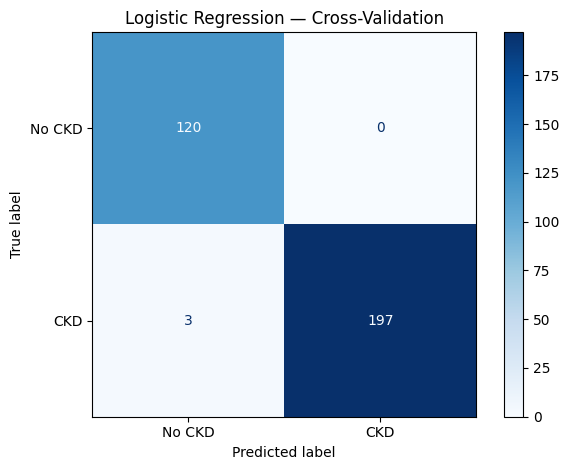

In [19]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Each patient is predicted by a model trained without that patient
cv_predictions = cross_val_predict(
    model,
    X_train,
    y_train,
    cv=cv
)

ConfusionMatrixDisplay.from_predictions(
    y_train,
    cv_predictions,
    labels=[0, 1],
    display_labels=["No CKD", "CKD"],
    cmap="Blues"
)

plt.title("Logistic Regression — Cross-Validation")
plt.tight_layout()
plt.show()

In [20]:
from google.colab import files

# Label the results with your model's name
results_to_save = results.copy()
results_to_save.insert(0, "Model", "Logistic Regression")

# Save and download the results table
results_to_save.to_csv("logistic_regression_cv_results.csv", index=False)
files.download("logistic_regression_cv_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

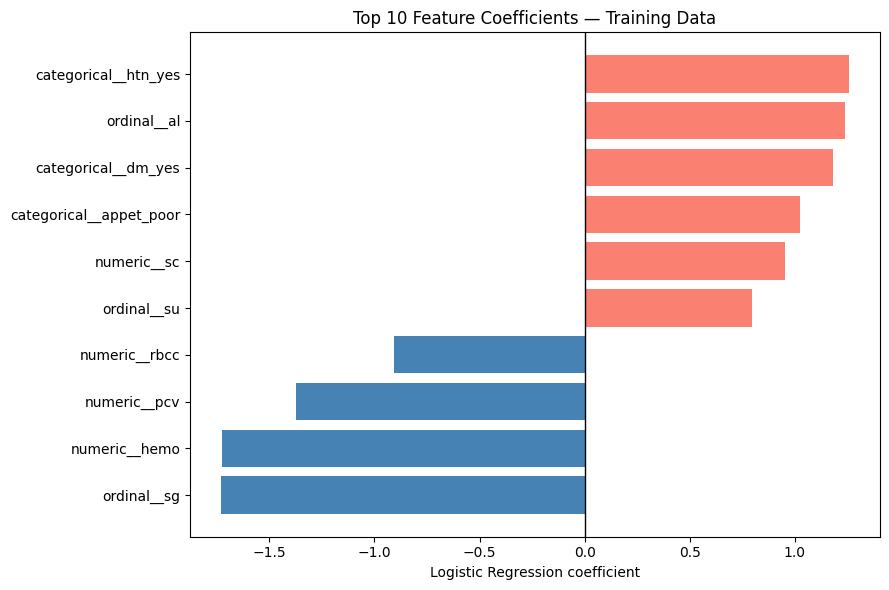

,Feature,Coefficient
11,ordinal__sg,-1.727354
7,numeric__hemo,-1.724551
8,numeric__pcv,-1.371103
10,numeric__rbcc,-0.904622
13,ordinal__su,0.797285
4,numeric__sc,0.954529
21,categorical__appet_poor,1.026623
19,categorical__dm_yes,1.181811
12,ordinal__al,1.240096
18,categorical__htn_yes,1.255683


In [21]:
# Fit using training patients only
model.fit(X_train, y_train)

# Get feature names and their learned coefficients
feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

coefficients = model.named_steps["classifier"].coef_[0]

feature_effects = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Select the 10 largest effects by absolute size
top_features = (
    feature_effects
    .assign(magnitude=lambda table: table["Coefficient"].abs())
    .nlargest(10, "magnitude")
    .sort_values("Coefficient")
)

colors = [
    "salmon" if value > 0 else "steelblue"
    for value in top_features["Coefficient"]
]

plt.figure(figsize=(9, 6))
plt.barh(
    top_features["Feature"],
    top_features["Coefficient"],
    color=colors
)
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Logistic Regression coefficient")
plt.title("Top 10 Feature Coefficients — Training Data")
plt.tight_layout()
plt.show()

top_features[["Feature", "Coefficient"]]

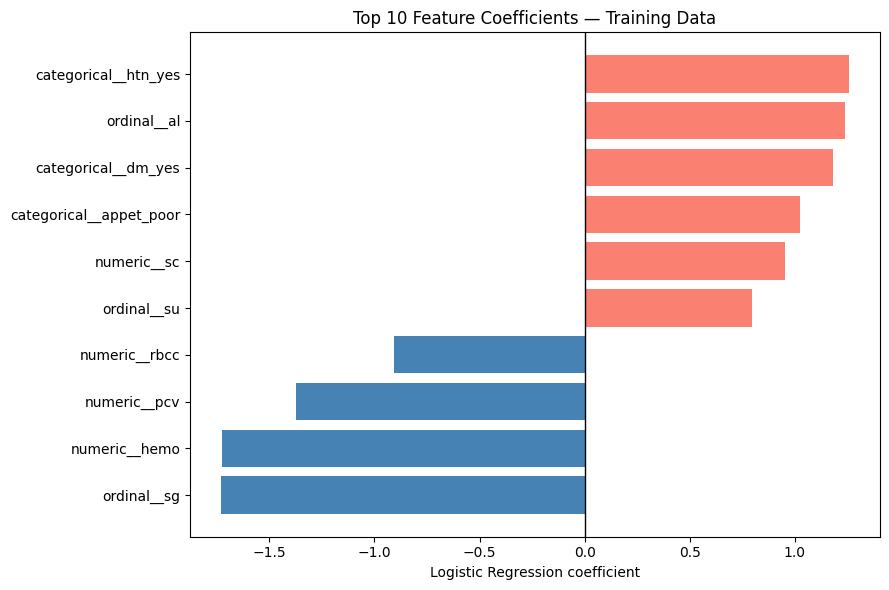

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
# Recreate and save the chart
fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    top_features["Feature"],
    top_features["Coefficient"],
    color=colors
)

ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Logistic Regression coefficient")
ax.set_title("Top 10 Feature Coefficients — Training Data")

fig.tight_layout()
fig.savefig("logistic_regression_features.png", dpi=300)
plt.show()

files.download("logistic_regression_features.png")

In [23]:
from sklearn.base import clone

# Remove these columns for a second experiment
drop_cols = ["rbc", "rbcc", "wbcc"]

reduced_numeric = [
    c for c in numeric_cols if c not in drop_cols
]
reduced_categorical = [
    c for c in categorical_cols if c not in drop_cols
]

reduced_preprocessor = ColumnTransformer([
    ("numeric", clone(numeric_pipeline), reduced_numeric),
    ("ordinal", clone(ordinal_pipeline), ordinal_cols),
    ("categorical", clone(categorical_pipeline), reduced_categorical)
])

reduced_model = Pipeline([
    ("preprocessor", reduced_preprocessor),
    ("classifier", clone(model.named_steps["classifier"]))
])

# Use the SAME training patients and validation folds
reduced_scores = cross_validate(
    reduced_model,
    X_train.drop(columns=drop_cols),
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc"
    },
    error_score="raise"
)

metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]

comparison = pd.DataFrame({
    "Metric": metrics,
    "Baseline: 24 features": [
        scores[f"test_{m}"].mean() for m in metrics
    ],
    "Reduced: 21 features": [
        reduced_scores[f"test_{m}"].mean() for m in metrics
    ]
})

comparison.round(4)

,Metric,Baseline: 24 features,Reduced: 21 features
0,accuracy,0.9906,0.9906
1,precision,1.0000,1.0000
2,recall,0.9850,0.9850
3,f1,0.9923,0.9923
4,roc_auc,0.9998,0.9998


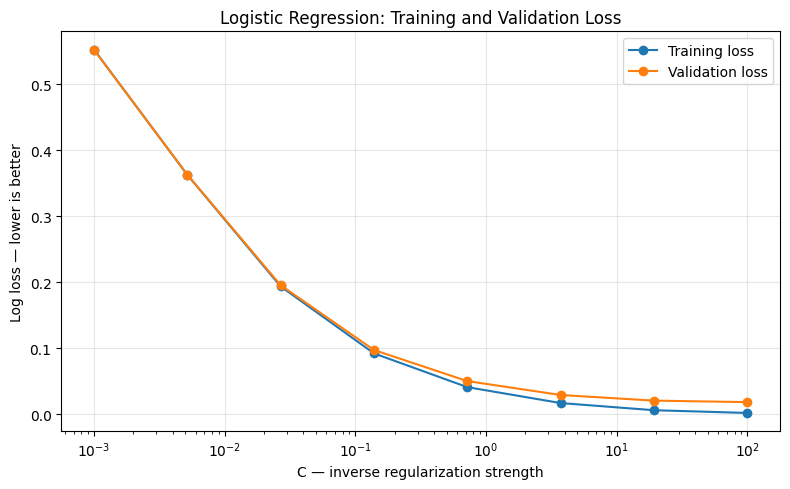

,C,Training log loss,Validation log loss
0,0.0010,0.5529,0.5525
1,0.0052,0.3630,0.3632
2,0.0268,0.1939,0.1956
3,0.1389,0.0924,0.0975
4,0.7197,0.0412,0.0503
5,3.7276,0.0171,0.0293
6,19.3070,0.0062,0.0207
7,100.0000,0.0021,0.0185


In [24]:
from sklearn.model_selection import validation_curve

# C controls regularization: smaller C = stronger regularization
c_values = np.logspace(-3, 2, 8)

train_scores, validation_scores = validation_curve(
    model,
    X_train,
    y_train,
    param_name="classifier__C",
    param_range=c_values,
    cv=cv,
    scoring="neg_log_loss",
    error_score="raise"
)

# Convert negative scores into positive loss
train_loss = -train_scores.mean(axis=1)
validation_loss = -validation_scores.mean(axis=1)

loss_results = pd.DataFrame({
    "C": c_values,
    "Training log loss": train_loss,
    "Validation log loss": validation_loss
})

fig, ax = plt.subplots(figsize=(8, 5))
ax.semilogx(c_values, train_loss, "o-", label="Training loss")
ax.semilogx(c_values, validation_loss, "o-", label="Validation loss")
ax.set_xlabel("C — inverse regularization strength")
ax.set_ylabel("Log loss — lower is better")
ax.set_title("Logistic Regression: Training and Validation Loss")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()

fig.savefig("logistic_regression_loss.png", dpi=300)
loss_results.to_csv("logistic_regression_loss.csv", index=False)
comparison.to_csv("logistic_regression_robustness.csv", index=False)

plt.show()
display(loss_results.round(4))

In [26]:
import zipfile
from google.colab import files

output_files = [
    "logistic_regression_cv_results.csv",
    "logistic_regression_features.png",
    "logistic_regression_robustness.csv",
    "logistic_regression_loss.csv",
    "logistic_regression_loss.png"
]

with zipfile.ZipFile("logistic_regression_outputs.zip", "w") as archive:
    for filename in output_files:
        archive.write(filename)

files.download("logistic_regression_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>